### 1. Load and Preprocess CIFAR-10 Dataset

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

# Data augmentation and normalization for training
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

batch_size = 64

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

100%|██████████| 170M/170M [12:01<00:00, 236kB/s]


### 2. Implement the PyTorch Model (Deeper CNN Architecture)

In [2]:
import torch.nn as nn
import torch.nn.functional as F

class DeeperCNN(nn.Module):
    def __init__(self):
        super(DeeperCNN, self).__init__()
        # Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout2d(0.25)

        # Block 2
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.dropout2 = nn.Dropout2d(0.3)

        # Block 3
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(256)
        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.bn6 = nn.BatchNorm2d(256)
        self.pool3 = nn.MaxPool2d(2, 2)
        self.dropout3 = nn.Dropout2d(0.4)

        # Fully Connected Layer
        self.fc1 = nn.Linear(256 * 4 * 4, 512)
        self.bn_fc = nn.BatchNorm1d(512)
        self.dropout_fc = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, 10)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.dropout1(self.pool1(x))

        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.dropout2(self.pool2(x))

        x = F.relu(self.bn5(self.conv5(x)))
        x = F.relu(self.bn6(self.conv6(x)))
        x = self.dropout3(self.pool3(x))

        x = x.view(-1, 256 * 4 * 4)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.dropout_fc(x)
        x = self.fc2(x)
        return x

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = DeeperCNN().to(device)
print(f"Using device: {device}")

Using device: cuda:0


### 3. Define Loss Function, Optimizer, and Train Model

In [3]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15)

epochs = 15
train_loss_history = []
train_acc_history = []
val_loss_history = []
val_acc_history = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(trainloader.dataset)
    epoch_acc = 100 * correct / total
    train_loss_history.append(epoch_loss)
    train_acc_history.append(epoch_acc)

    # Validation Phase
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data in testloader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(testloader.dataset)
    epoch_val_acc = 100 * val_correct / val_total
    val_loss_history.append(epoch_val_loss)
    val_acc_history.append(epoch_val_acc)

    scheduler.step()

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.2f}% | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")
print("Finished Training")

Epoch [1/15] | Train Loss: 1.6383 | Train Acc: 39.87% | Val Loss: 1.1568 | Val Acc: 58.17%
Epoch [2/15] | Train Loss: 1.2515 | Train Acc: 55.12% | Val Loss: 0.9051 | Val Acc: 67.71%
Epoch [3/15] | Train Loss: 1.0626 | Train Acc: 62.27% | Val Loss: 0.7935 | Val Acc: 71.74%
Epoch [4/15] | Train Loss: 0.9559 | Train Acc: 66.55% | Val Loss: 0.6893 | Val Acc: 76.04%
Epoch [5/15] | Train Loss: 0.8700 | Train Acc: 69.41% | Val Loss: 0.6414 | Val Acc: 77.35%
Epoch [6/15] | Train Loss: 0.8074 | Train Acc: 71.74% | Val Loss: 0.6117 | Val Acc: 79.22%
Epoch [7/15] | Train Loss: 0.7510 | Train Acc: 74.03% | Val Loss: 0.5467 | Val Acc: 81.21%
Epoch [8/15] | Train Loss: 0.7041 | Train Acc: 75.81% | Val Loss: 0.5317 | Val Acc: 81.75%
Epoch [9/15] | Train Loss: 0.6565 | Train Acc: 77.23% | Val Loss: 0.4993 | Val Acc: 82.91%
Epoch [10/15] | Train Loss: 0.6105 | Train Acc: 78.96% | Val Loss: 0.4701 | Val Acc: 83.53%
Epoch [11/15] | Train Loss: 0.5748 | Train Acc: 80.09% | Val Loss: 0.4535 | Val Acc: 84.6

### 4. Evaluate and Visualize Results

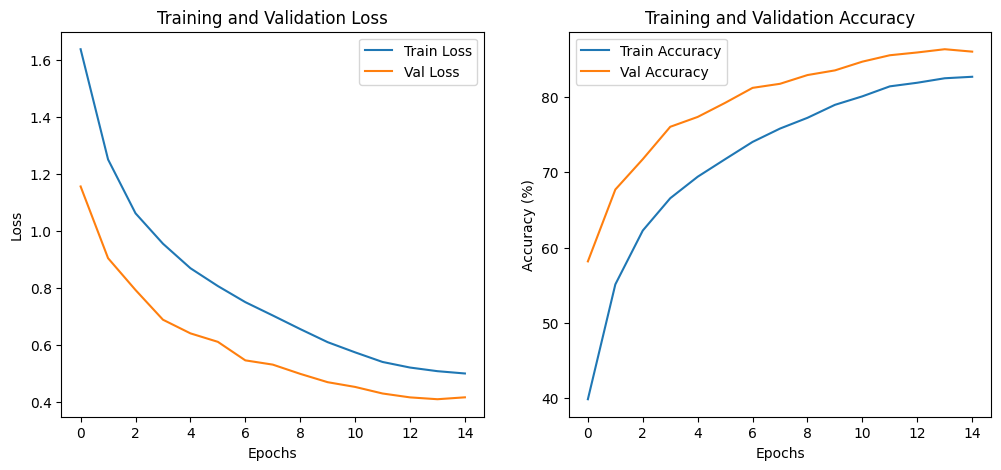

In [4]:
import matplotlib.pyplot as plt

# Plot Loss curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_loss_history, label='Train Loss')
plt.plot(val_loss_history, label='Val Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(train_acc_history, label='Train Accuracy')
plt.plot(val_acc_history, label='Val Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

### 5. Calculate and Plot Confusion Matrix for Test Set

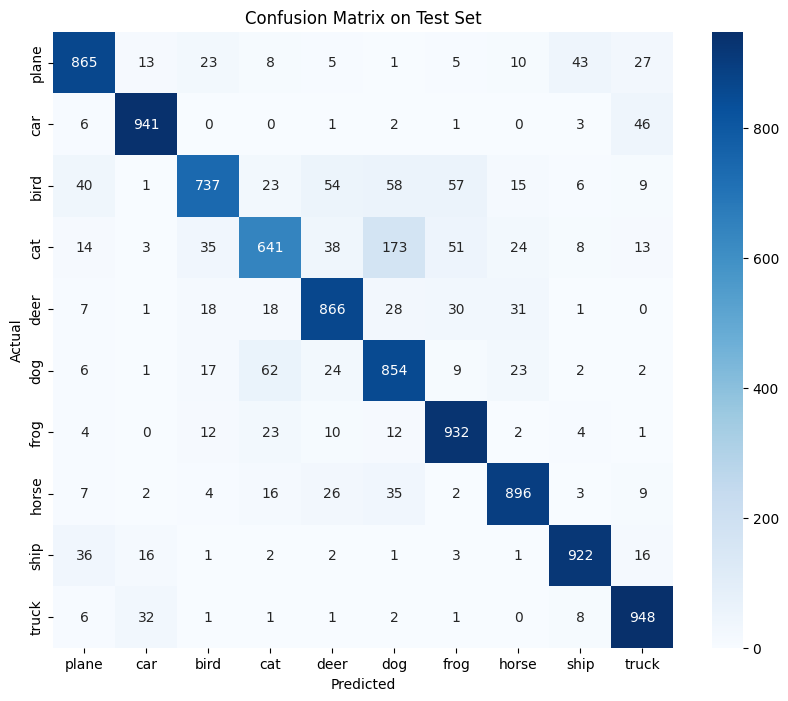

In [5]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for data in testloader:
        images, labels = data[0].to(device), data[1].to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Visualize confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap='Blues')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix on Test Set')
plt.show()